# 05 · Results

## What this notebook does
Notebook 04 trained all models on a Colab GPU and saved the results. Here we answer the three research questions
from notebook 01, using only those saved files (`results/results.csv` and `results/calibration/`). Nothing is retrained.

| Question | Section |
|---|---|
| 1. How accurately can speed be forecast 1–3 hours ahead? | 1 · Accuracy, 2 · Stability across months |
| 2. How much do neighbours, calendar, weather and fuel events help? | 3 · Feature groups (ablation) |
| 3. Are the uncertainty intervals reliable? | 4 · Uncertainty and calibration |
| Where and when does the model fail? | 5 · Example forecasts, 6 · Errors by hour, 7 · Conditions |
| What could be improved? | 8 · Next steps |

**Models.** Two simple baselines (*persistence*: the speed stays as it is now; *seasonal naive*: the speed at the
same hour last week), XGBoost with quantile output, and the kinematic LSTM. XGBoost and LSTM were trained with
3 random seeds; we report the mean and the standard deviation over seeds.

**Evaluation data.** Test period November–December 2024, **measured hours only** (1,249 hours per horizon).
Filled hours are never scored (see 02).

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src.data import ROOT, FIG_DIR
from src.models import evaluate
from src.calibration import calibrate

BLUE, ORANGE, GREY, LIGHT='#2E6FBA', '#D9822B', '#8A8F98', '#C9D7EA'
COLORS={'xgboost':BLUE, 'lstm':ORANGE, 'seasonal_naive':GREY, 'persistence':'#C4C7CC'}
NAMES={'xgboost':'XGBoost', 'lstm':'LSTM', 'seasonal_naive':'Seasonal naive', 'persistence':'Persistence'}
Q=['q05', 'q25', 'q50', 'q75', 'q95']
plt.rcParams.update({
    'figure.dpi':110, 'savefig.dpi':300, 'savefig.bbox':'tight',
    'font.family':'serif', 'font.size':10,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.grid':True, 'grid.color':'#E5E5E5', 'grid.linewidth':0.6,
})
def save(fig, name):
    fig.savefig(FIG_DIR/f'{name}.png')

res=pd.read_csv(ROOT/'results'/'results.csv')
test=res[res['stage']=='test']
wf=res[res['stage']=='walkforward']

def load_pred(model, h, seed):
    return pd.read_parquet(ROOT/'results'/'calibration'/f'{model}_h{h}_s{seed}.parquet')

print(f"{len(res)} runs: {len(test)} test, {len(wf)} walk-forward")

204 runs: 96 test, 108 walk-forward


## 1 · Accuracy on the test period

> 🔍 **Why this figure?** The first question is simply how good the forecasts are, and how quickly they get worse
> when we look further ahead. The baselines show what a forecast without any learning would achieve.

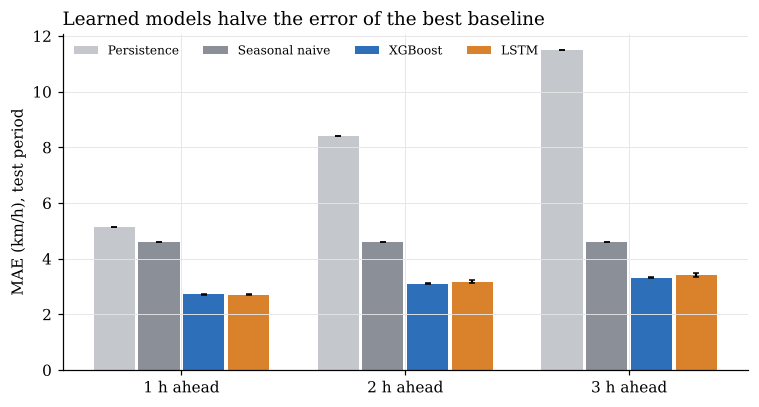

MAE   RMSE   MAPE    R2     MAE ± sd
horizon model                                                 
1       persistence      5.14   7.23  12.20  0.83         5.14
        seasonal_naive   4.62   6.65  11.21  0.85         4.62
        xgboost          2.72   3.72   6.65  0.95  2.72 ± 0.00
        lstm             2.71   3.67   6.51  0.96  2.71 ± 0.02
2       persistence      8.41  11.71  19.89  0.55         8.41
        seasonal_naive   4.62   6.65  11.21  0.85         4.62
        xgboost          3.10   4.27   7.60  0.94  3.10 ± 0.02
        lstm             3.17   4.37   7.60  0.94  3.17 ± 0.05
3       persistence     11.49  15.38  27.20  0.22        11.49
        seasonal_naive   4.62   6.65  11.21  0.85         4.62
        xgboost          3.32   4.60   8.08  0.93  3.32 ± 0.02
        lstm             3.42   4.73   8.24  0.93  3.42 ± 0.07

In [2]:
full=test[test['ablation']=='full']
table=full.groupby(['horizon', 'model'])[['MAE', 'RMSE', 'MAPE', 'R2']].agg(['mean', 'std'])
order=['persistence', 'seasonal_naive', 'xgboost', 'lstm']

fig, ax=plt.subplots(figsize=(7, 3.8))
width=0.2
for i, m in enumerate(order):
    s=full[full['model']==m].groupby('horizon')['MAE']
    mean, std=s.mean(), s.std().fillna(0)
    ax.bar(mean.index+(i-1.5)*width, mean, width=width*0.92, yerr=std, capsize=2, color=COLORS[m], label=NAMES[m])
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(['1 h ahead', '2 h ahead', '3 h ahead'])
ax.set_ylabel('MAE (km/h), test period')
ax.set_title('Learned models halve the error of the best baseline', loc='left')
ax.legend(frameon=False, ncol=4, fontsize=8, loc='upper left')
fig.tight_layout(); save(fig, 'fig17_accuracy'); plt.show()

summary=full.groupby(['horizon', 'model'])[['MAE', 'RMSE', 'MAPE', 'R2']].mean().round(2)
summary['MAE ± sd']=full.groupby(['horizon', 'model'])['MAE'].agg(lambda s: f'{s.mean():.2f} ± {s.std():.2f}' if len(s)>1 else f'{s.mean():.2f}')
summary.reindex(order, level='model')

**Findings.** Both learned models are far better than the baselines. One hour ahead, XGBoost and the LSTM reach an
MAE of about **2.7 km/h** (R² = 0.95–0.96), while the best baseline has 4.6 km/h. The error grows slowly with the
horizon (about 3.3 km/h at 3 hours), whereas *persistence* becomes useless after one hour. One hour ahead the two
models are equal; at 2 and 3 hours XGBoost is slightly better. The differences between seeds are small (≤ 0.07 km/h).

Note: the earlier version of this study reported a similar MAE (2.75 km/h), but it was calculated partly on filled
hours. The value here comes from a leak-free pipeline and measured hours only.

## 2 · Stability across months (walk-forward)

> 🔍 **Why this figure?** A single test period can be lucky. In walk-forward validation each model is trained on the
> months before and tested on the next month, from May to October. A good model should be good in every month,
> not only in November–December.

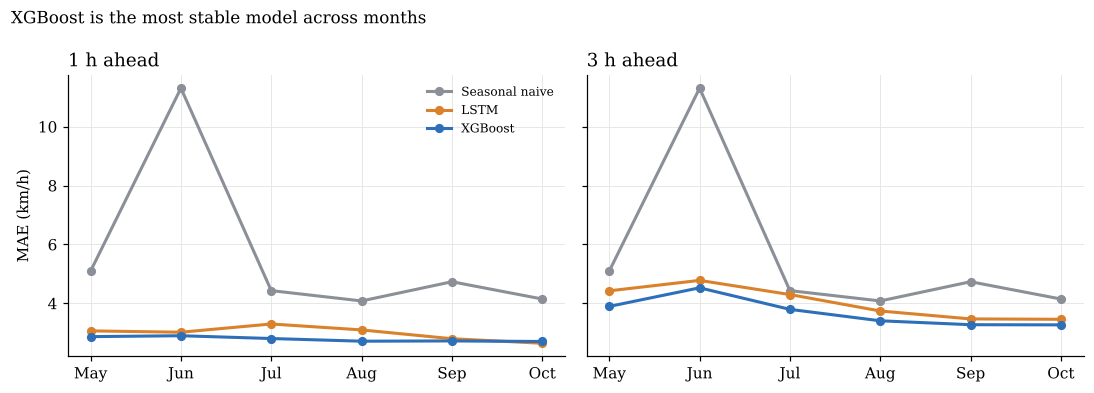

XGBoost better than LSTM in 17 of 18 month-horizon pairs


mean   std
horizon model              
1       lstm     2.99  0.23
        xgboost  2.79  0.08
2       lstm     3.67  0.33
        xgboost  3.40  0.29
3       lstm     4.03  0.55
        xgboost  3.69  0.49

In [3]:
w=wf[wf['ablation']=='full']
fig, axes=plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, h in zip(axes, [1, 3]):
    for m in ['seasonal_naive', 'lstm', 'xgboost']:
        s=w[(w['model']==m)&(w['horizon']==h)].sort_values('eval_month')
        ax.plot(s['eval_month'], s['MAE'], marker='o', ms=5, lw=2, color=COLORS[m], label=NAMES[m])
    ax.set_xticks(range(5, 11)); ax.set_xticklabels(['May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct'])
    ax.set_title(f'{h} h ahead', loc='left')
axes[0].set_ylabel('MAE (km/h)')
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('XGBoost is the most stable model across months', x=0.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig18_walkforward'); plt.show()

p=w[w['model'].isin(['xgboost', 'lstm'])].pivot_table(index=['eval_month', 'horizon'], columns='model', values='MAE')
print(f"XGBoost better than LSTM in {(p['xgboost']<p['lstm']).sum()} of {len(p)} month-horizon pairs")
w[w['model'].isin(['xgboost', 'lstm'])].groupby(['horizon', 'model'])['MAE'].agg(['mean', 'std']).round(2)

**Findings.** XGBoost has a lower error than the LSTM in **17 of 18** month–horizon pairs, and its error changes
less from month to month (standard deviation 0.08 vs 0.23 km/h one hour ahead). The LSTM matched XGBoost on the
test period, but it is less reliable across seasons. The seasonal-naive baseline fails badly in June (Kurban Bayramı:
"last week" is not a good guide for a holiday week), while the learned models stay stable because they know the calendar.

> ➡️ **Main model:** XGBoost. It is as accurate as the LSTM, more stable, and about ten times faster to train.

## 3 · Which information helps? (ablation)

> 🔍 **Why this figure?** Each feature group was removed in turn and the model was retrained (3 seeds each).
> The bar shows how much the test error **increases** without that group. A bar near zero means the group adds nothing.

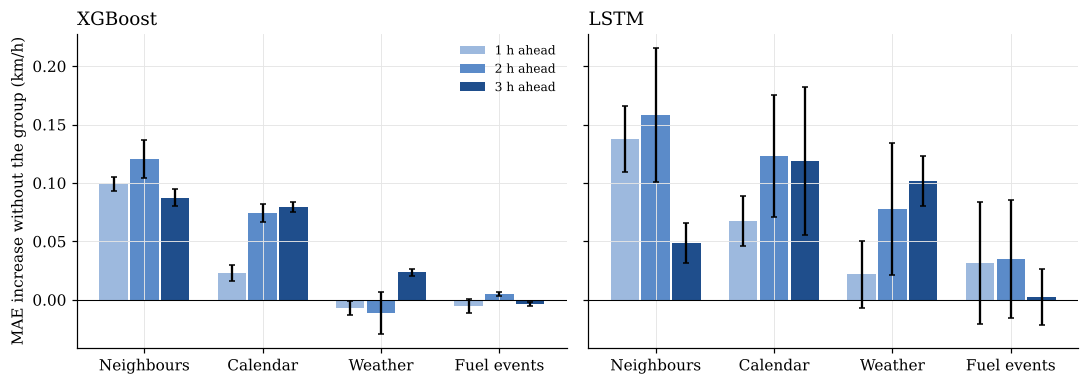

ablation         no_neighbours  no_calendar  no_weather  no_fuel
model   horizon                                                 
lstm    1                0.138        0.067       0.022    0.031
        2                0.158        0.123       0.077    0.035
        3                0.049        0.119       0.102    0.002
xgboost 1                0.099        0.023      -0.007   -0.006
        2                0.120        0.074      -0.011    0.005
        3                0.087        0.080       0.024   -0.003

In [4]:
groups=['no_neighbours', 'no_calendar', 'no_weather', 'no_fuel']
labels=['Neighbours', 'Calendar', 'Weather', 'Fuel events']
base=test[test['ablation']=='full'].groupby(['model', 'horizon'])['MAE'].mean()

fig, axes=plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
shades=['#9DB9DE', '#5B8BC9', '#1F4E8C']
for ax, m in zip(axes, ['xgboost', 'lstm']):
    for j, h in enumerate([1, 2, 3]):
        d=[test[(test['model']==m)&(test['horizon']==h)&(test['ablation']==g)]['MAE'] for g in groups]
        delta=[x.mean()-base[(m, h)] for x in d]
        err=[x.std() for x in d]
        ax.bar(np.arange(4)+(j-1)*0.26, delta, width=0.24, yerr=err, capsize=2, color=shades[j], label=f'{h} h ahead')
    ax.axhline(0, color='black', lw=0.7)
    ax.set_xticks(range(4)); ax.set_xticklabels(labels)
    ax.set_title(NAMES[m], loc='left')
axes[0].set_ylabel('MAE increase without the group (km/h)')
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, 'fig19_ablation'); plt.show()

abl=test[test['model'].isin(['xgboost', 'lstm'])].groupby(['model', 'horizon', 'ablation'])['MAE'].mean().unstack()
(abl[groups].sub(abl['full'], axis=0)).round(3)

**Findings.**
- **Neighbours help the most:** without them the error rises by 0.05–0.16 km/h (2–5%) for both models and all horizons.
  In 01 we saw that neighbours do not clearly "see congestion first" at hourly resolution, but they still carry useful
  information about the state of the road network.
- **The calendar matters more for longer horizons:** for XGBoost, +0.02 km/h at 1 hour but +0.08 km/h at 3 hours.
  The further ahead we look, the more the forecast relies on the usual weekly and holiday pattern.
- **Weather and fuel events add almost nothing.** For XGBoost, removing weather even lowers the error slightly at
  1–2 hours, and the fuel effect is within ±0.005 km/h. Rain is rare in the test period, and only 20 fuel nights
  could be observed (see 01). These are honest negative results.
- The LSTM results vary more between seeds (larger error bars), so its ablation differences are less certain than those of XGBoost.

## 4 · Uncertainty and calibration

> 🔍 **Why?** The model gives an interval, for example "between 38 and 52 km/h". A 90% interval should contain the
> real speed in about 90% of the hours. If it contains it less often, the interval is **too narrow** and gives a false
> feeling of certainty.

**Method: conformalized quantile regression (CQR).** On the validation period (September–October) we measure how
far the real speeds fall outside the predicted interval. The interval is then widened by the amount that would have
given 90% coverage there. This needs no retraining and has a statistical coverage guarantee if the validation and
test periods behave alike (Romano et al., 2019).

Limitation: the validation period was also used for early stopping, so it is not fully independent of the model.

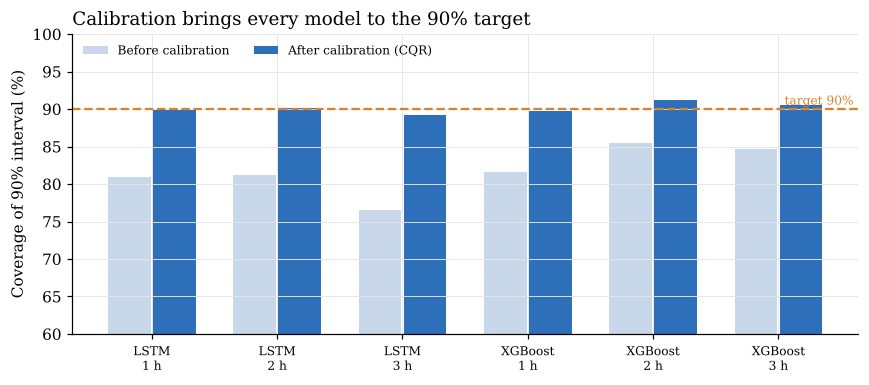

coverage_before  coverage_after  width_before  width_after  \
model   horizon                                                               
lstm    1                   80.9            89.9           9.5         11.6   
        2                   81.2            90.2          10.9         13.6   
        3                   76.6            89.2          10.5         13.9   
xgboost 1                   81.6            89.8           9.4         11.3   
        2                   85.5            91.2          11.9         13.9   
        3                   84.7            90.6          12.7         14.8   

                 coverage50_before  coverage50_after  
model   horizon                                       
lstm    1                     41.1              49.2  
        2                     41.3              50.1  
        3                     38.4              48.7  
xgboost 1                     38.7              47.8  
        2                     40.3              50.2  
        3                     41.3              49.3

In [5]:
rows=[]
for m in ['xgboost', 'lstm']:
    for h in [1, 2, 3]:
        for seed in [1, 2, 3]:
            p=load_pred(m, h, seed)
            val, te=p[p['split']=='val'], p[p['split']=='test']
            raw=evaluate(te['y'].values, te[Q].values)
            cal, off=calibrate(val, te)
            new=evaluate(te['y'].values, cal[Q].values)
            rows.append({'model':m, 'horizon':h, 'seed':seed,
                         'coverage_before':raw['PICP90'], 'coverage_after':new['PICP90'],
                         'width_before':raw['MPIW90'], 'width_after':new['MPIW90'],
                         'coverage50_before':raw['PICP50'], 'coverage50_after':new['PICP50']})
calib=pd.DataFrame(rows).groupby(['model', 'horizon']).mean().drop(columns='seed').round(1)

fig, ax=plt.subplots(figsize=(8, 3.6))
x=np.arange(6)
lab=[f'{NAMES[m]}\n{h} h' for m, h in calib.index]
ax.bar(x-0.18, calib['coverage_before'], width=0.34, color=LIGHT, label='Before calibration')
ax.bar(x+0.18, calib['coverage_after'], width=0.34, color=BLUE, label='After calibration (CQR)')
ax.axhline(90, color=ORANGE, lw=1.5, ls='--')
ax.text(5.6, 90.6, 'target 90%', color=ORANGE, ha='right', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(lab, fontsize=8)
ax.set_ylim(60, 100); ax.set_ylabel('Coverage of 90% interval (%)')
ax.set_title('Calibration brings every model to the 90% target', loc='left')
ax.legend(frameon=False, fontsize=8, loc='upper left', ncol=2)
fig.tight_layout(); save(fig, 'fig20_calibration'); plt.show()
calib

**Findings.** Before calibration, the 90% intervals cover only 77–86% of the test hours. After calibration, coverage is
**89–91%** for every model and horizon, and the 50% intervals cover 48–50%. The price is a wider interval: on average
11–15 km/h instead of 9–13 km/h. An honest interval is more useful for a traffic operator than a narrow one that is
often wrong.

## 5 · What the forecasts look like

> 🔍 **Why this figure?** Metrics are averages. A plot of one week shows how the forecast behaves during the daily rise
> and fall of congestion, and how the interval widens when the model is less sure. We show XGBoost (seed 1) with
> calibrated 90% intervals, 1 hour and 3 hours ahead.

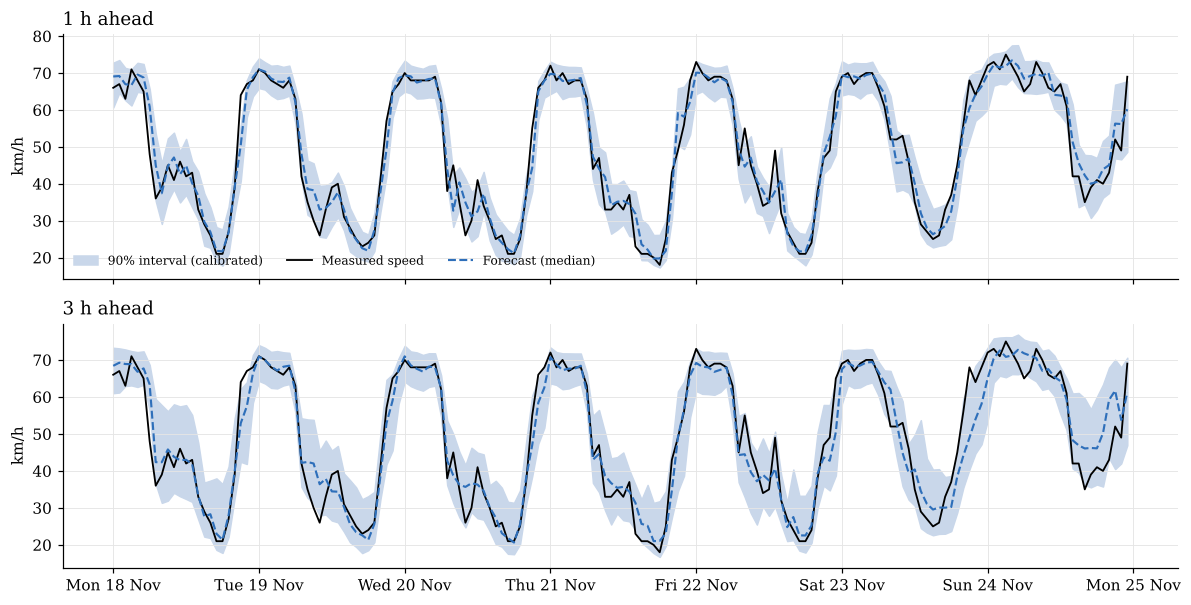

In [6]:
week=('2024-11-18', '2024-11-24 23:00')
fig, axes=plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
for ax, h in zip(axes, [1, 3]):
    p=load_pred('xgboost', h, 1)
    cal, _=calibrate(p[p['split']=='val'], p[p['split']=='test'])
    cal=cal.set_index('target_time').sort_index().loc[week[0]:week[1]]
    ax.fill_between(cal.index, cal['q05'], cal['q95'], color=LIGHT, label='90% interval (calibrated)')
    ax.plot(cal.index, cal['y'], color='black', lw=1.2, label='Measured speed')
    ax.plot(cal.index, cal['q50'], color=BLUE, lw=1.4, ls='--', label='Forecast (median)')
    ax.set_ylabel('km/h'); ax.set_title(f'{h} h ahead', loc='left')
axes[0].legend(frameon=False, fontsize=8, ncol=3, loc='lower left')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b'))
fig.tight_layout(); save(fig, 'fig21_example_week'); plt.show()

**Findings.** The forecast follows the daily cycle closely. The largest errors appear at the sharp transitions:
when congestion starts in the afternoon and when it clears in the evening. Three hours ahead, the forecast is
smoother and the interval is wider around these transitions, which is the right behaviour: this is where the future
is most uncertain.

## 6 · When is the model wrong?

> 🔍 **Why this figure?** In 01 we found two traffic regimes with fast switches between them. If the model struggles,
> it should be at the hours when the regime changes.

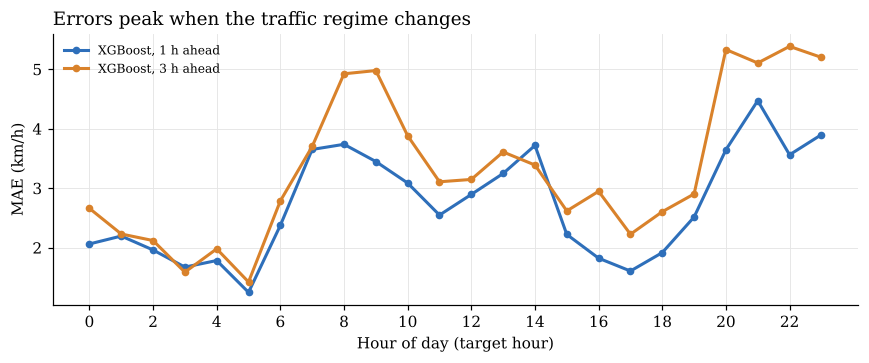

In [7]:
fig, ax=plt.subplots(figsize=(8, 3.4))
for h, color in zip([1, 3], [BLUE, ORANGE]):
    errs=[]
    for seed in [1, 2, 3]:
        p=load_pred('xgboost', h, seed)
        te=p[p['split']=='test']
        errs.append((te['y']-te['q50']).abs().groupby(pd.to_datetime(te['target_time']).dt.hour).mean())
    e=pd.concat(errs, axis=1).mean(axis=1)
    ax.plot(e.index, e.values, marker='o', ms=4, lw=2, color=color, label=f'XGBoost, {h} h ahead')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('Hour of day (target hour)'); ax.set_ylabel('MAE (km/h)')
ax.set_title('Errors peak when the traffic regime changes', loc='left')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, 'fig22_error_by_hour'); plt.show()

**Findings.** The error is lowest at night, when traffic flows freely and predictably. It is highest around
**07:00–09:00** (congestion starts), **14:00** (the afternoon slowdown begins) and **20:00–23:00** (congestion clears).
During the congested hours themselves (16:00–18:00) the error is low: once traffic is stuck, it stays stuck.
These are exactly the regime transitions found in 01. Better information about *when* a transition will start, for
example real-time incident data, is the most promising way to improve the model.

## 7 · Where does the model do well, and where not?

> 🔍 **Why this table?** Section 6 looked at the hour of day. Here we split the test hours by traffic state, day type,
> weather and data quality, to see under which conditions the main model (XGBoost, mean of 3 seeds) works well.

In [8]:
df=pd.read_parquet(ROOT/'data'/'processed'/'dataset.parquet')
rows=[]
for h in [1, 3]:
    preds=[load_pred('xgboost', h, s) for s in [1, 2, 3]]
    te=preds[0][preds[0]['split']=='test'].copy()
    te['q50']=np.mean([p.loc[p['split']=='test', 'q50'].values for p in preds], axis=0)
    t=pd.to_datetime(te['target_time']); origin=t-pd.Timedelta(hours=h)
    err=(te['y']-te['q50']).abs().values
    change=(te['y'].values-df.loc[origin, 'speed'].values)
    conditions={
        'Free flow (≥ 60 km/h)':te['y'].values>=60,
        'Congested (< 40 km/h)':te['y'].values<40,
        'In between (40–60 km/h)':(te['y'].values>=40)&(te['y'].values<60),
        'Weekday':t.dt.dayofweek.values<5,
        'Weekend':t.dt.dayofweek.values>=5,
        'Dry':df.loc[t, 'rain'].values==0,
        'Rain':df.loc[t, 'rain'].values>0.1,
        'Current speed was filled':df.loc[origin, 'speed_filled'].values==1,
        'Speed changes > 15 km/h':np.abs(change)>15,
        'All test hours':np.ones(len(te), bool),
    }
    for name, m in conditions.items():
        rows.append({'condition':name, 'horizon':f'{h} h', 'hours':int(m.sum()), 'MAE':err[m].mean()})
cond=pd.DataFrame(rows).pivot_table(index='condition', columns='horizon', values=['MAE', 'hours'], sort=False)
cond.round(2)

MAE         hours        
horizon                    1 h   3 h     1 h     3 h
condition                                           
Free flow (≥ 60 km/h)     2.03  2.57   469.0   469.0
Congested (< 40 km/h)     2.62  3.26   493.0   493.0
In between (40–60 km/h)   3.95  4.58   287.0   287.0
Weekday                   2.63  3.07   916.0   916.0
Weekend                   2.89  3.93   333.0   333.0
Dry                       2.75  3.32   989.0   989.0
Rain                      2.49  3.37   165.0   165.0
Current speed was filled  4.75  3.32    13.0    31.0
Speed changes > 15 km/h   5.51  4.35    82.0   392.0
All test hours            2.70  3.30  1249.0  1249.0

**Findings.**
- **Best in free flow (MAE ≈ 2.0 km/h one hour ahead) and good in stable congestion (≈ 2.6).** When the regime does not
  change, the model is very accurate.
- **Worst in the 40–60 km/h zone (≈ 4.0) and when speed changes by more than 15 km/h (≈ 5.5).** These are the
  transitions between regimes, the same weakness seen in section 6.
- **Weekends are harder, especially further ahead** (3.9 vs 3.1 km/h at 3 hours). Weekend traffic is less regular, and the
  training data contains only about 35 weekends.
- **Rain does not make the forecast worse.** This agrees with the ablation: at Mahmutbey, rain in the test period did not
  change traffic enough to matter.
- **Filled inputs:** the first hour after an outage is harder (MAE ≈ 4.8, but only 13 hours), and the effect disappears
  at longer horizons.

## 8 · How could the model be improved?

| Weakness | Idea | Expected effect |
|---|---|---|
| Regime transitions (start and end of congestion) | Add information that announces a transition: real-time incident and roadworks data, speed changes further away on the network, a separate model for "will congestion start?" | Largest possible gain; this is where most of the error is |
| Only one year of data | Train on several years of IBB data (available from 2020). Seasonal and holiday patterns would be seen more than once, and the test months would also appear in training | More robust, especially for holidays and weekends |
| Weekends | More data (see above) and features for leisure traffic, such as shopping and event days | Better weekend accuracy |
| Neighbours help but are simple features | A network model (graph neural network) over many cells instead of six hand-picked neighbours | Uses the spatial information more fully |
| Hourly resolution | Use 5–15 minute data if it becomes available | Transitions could be detected before they are complete |
| Weather adds nothing | Use **weather forecasts** and only extreme events (heavy rain, snow) instead of all hours | Weather may matter on the few days that really count |
| Calibration uses the validation period also used for early stopping | A separate calibration period, or adaptive conformal methods for time series that adjust coverage over time | More trustworthy intervals |


## Summary

| Question | Answer |
|---|---|
| How accurate? | MAE ≈ **2.7 km/h** 1 h ahead (R² 0.95), ≈ **3.3 km/h** 3 h ahead; about half the error of the best baseline |
| Which model? | **XGBoost**: as accurate as the LSTM, better in 17 of 18 walk-forward months, much faster to train |
| What helps? | **Neighbour cells** (2–5% lower error) and the **calendar** (more at longer horizons). Weather and fuel events: no measurable gain |
| Reliable intervals? | Raw intervals are too narrow (77–86% coverage); after **CQR calibration** coverage is 89–91% |
| Where does it fail? | At regime transitions (start and end of congestion) and on weekends; best in free flow |
| How to improve? | Transition signals (incidents), more years of data, a network model |

**Next step:** a small demo (Streamlit + Docker) that shows the calibrated forecasts, and the paper.